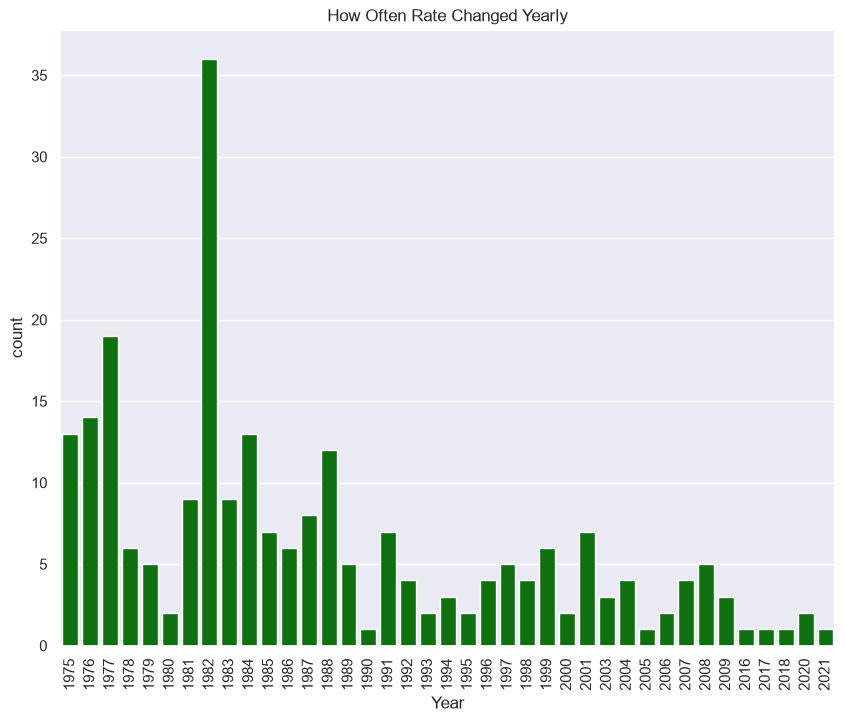

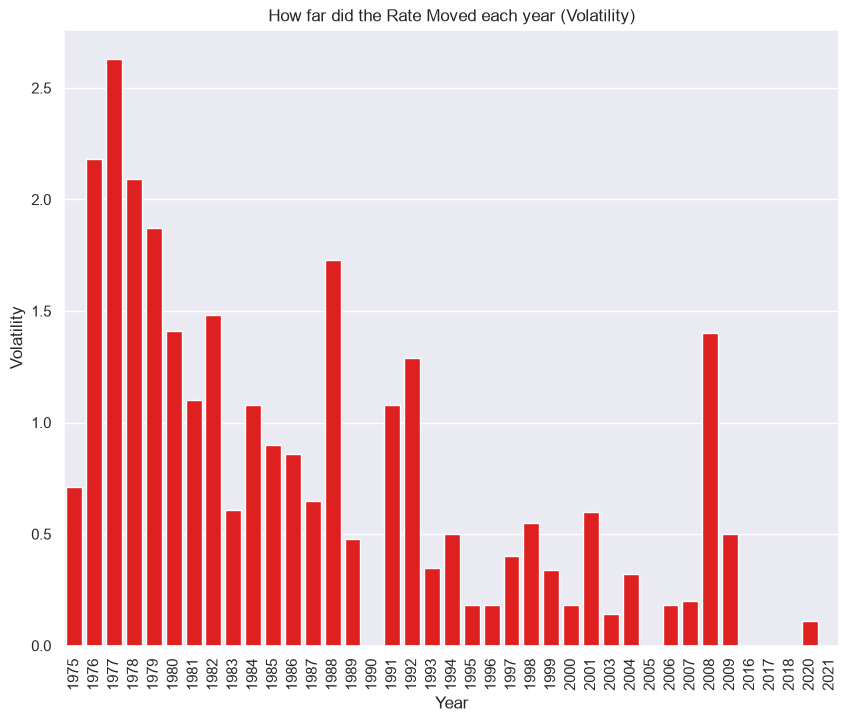

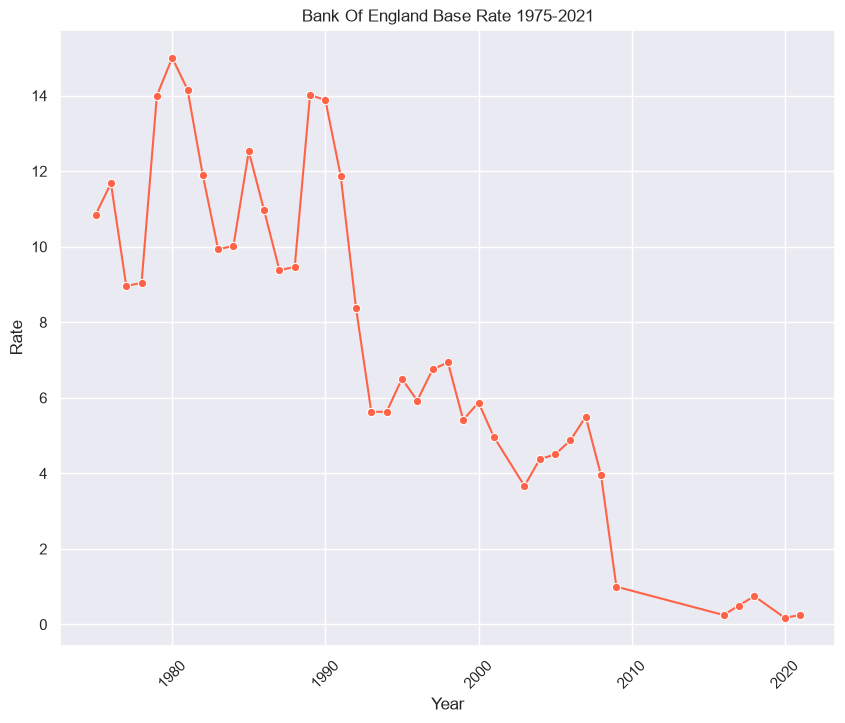

     Month Name  Rate
Year                 
1997   November  7.25
1997     August  7.00
1997       July  6.75
1997       June  6.50
1997        May  6.25
2008   February  5.25
2008      April  5.00
2008    October  4.50
2008   November  3.00
2008   December  2.00
2016     August  0.25
2020      March  0.25
2020      March  0.10


,Year,Month Name,Rate
0,2021,December,0.25
1,2020,March,0.10
2,2020,March,0.25
3,2018,August,0.75


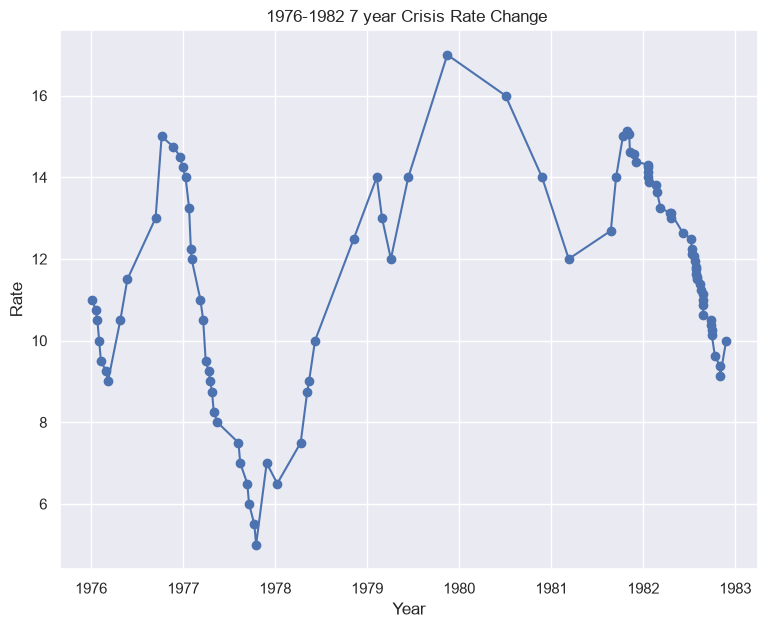

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
data = pd.read_csv("BOE.csv")
db= data.copy()
db.head()
db['Date Changed'] =pd.to_datetime(db['Date Changed'], format ='%d %b %y')
db['Day']=db['Date Changed'].dt.day
db['Month Name']=db['Date Changed'].dt.month_name()
db['Year']=db['Date Changed'].dt.year
yearly_avg=db.groupby('Year',as_index= False)['Rate'].mean().reset_index()
db['Rate'].std()
yearly_stats= db.groupby('Year',as_index= False)['Rate'].agg(['mean','std','median','max','min','count'])
yearly_stats['Range']= yearly_stats['max']-yearly_stats['min']
yearly_stats=yearly_stats.round(2)
yearly_stats.fillna(0)
sns.set(rc={'figure.figsize': (10, 8)})
sns.countplot(data=db, x='Year', color= 'green')
plt.xticks(rotation=90)
plt.title('How Often Rate Changed Yearly')
plt.show()
sns.barplot(data=yearly_stats, x = 'Year',y= 'std',color= 'red')
plt.xticks(rotation=90)
plt.title('How far did the Rate Moved each year (Volatility)')
plt.ylabel('Volatility')
fig, ax = plt.subplots(figsize=(10, 8))
sns.lineplot(data=yearly_avg, x='Year', y='Rate', marker='o',color='tomato')
plt.title('Bank Of England Base Rate 1975-2021')
plt.xticks(rotation=45)
plt.show()
pst_analysis = db[db['Year'].isin([1997, 2008, 2016, 2020])][['Year', 'Month Name','Rate']].set_index('Year')
print(pst_analysis.sort_values(by='Rate', ascending=False))
db.to_csv("cleaned_rate.csv",index = False)
check=pd.read_csv("cleaned_rate.csv")
check= check.set_index('Date Changed')
check.head()

crisis = db[(db['Year'] >= 1976) & (db['Year'] <= 1982)] #7 year crisis 
fig, ax = plt.subplots(figsize=(9,7))
ax.plot(crisis['Date Changed'], crisis['Rate'], marker='o')
ax.set_title('1976-1982 7 year Crisis Rate Change ')
ax.set_xlabel("Year")
ax.set_ylabel("Rate")

db[db['Year'].isin([2018,2019,2020,2021])][['Year','Month Name','Rate']]
